In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt, os, urllib.request
# Sample images download (Colab mein chalega)
imgs = {'coins.png':'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/smarties.png',
        'road.jpg':'https://raw.githubusercontent.com/udacity/CarND-LaneLines-P1/master/test_images/solidWhiteRight.jpg'}
for f,u in imgs.items():
    if not os.path.exists(f): urllib.request.urlretrieve(u,f)
def show(im, title, size=(10,6)):
    plt.figure(figsize=size); plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); plt.title(title); plt.axis('off'); plt.show()

## Question 1 — Circle Detection with `cv2.HoughCircles()`

Total circles detected: 12


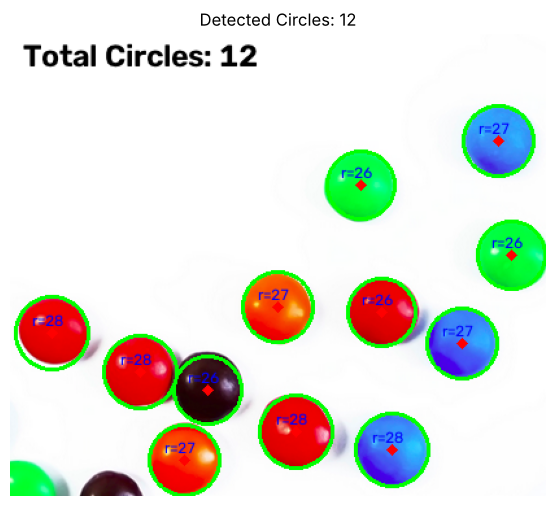

In [ ]:
img = cv2.imread('coins.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.medianBlur(gray, 5)          # noise kam karo, false circles se bachne ke liye

# Final tuned parameters
DP, MIN_DIST, PARAM1, PARAM2, MIN_R, MAX_R = 1, 30, 100, 30, 15, 40
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=DP, minDist=MIN_DIST,
                           param1=PARAM1, param2=PARAM2, minRadius=MIN_R, maxRadius=MAX_R)
out = img.copy(); count = 0
if circles is not None:
    circles = np.uint16(np.around(circles.reshape(-1, 3)))
    count = len(circles)
    for (x, y, r) in circles:
        cv2.circle(out, (x, y), r, (0, 255, 0), 2)        # circle boundary
        cv2.circle(out, (x, y), 2, (0, 0, 255), 3)        # center mark
        cv2.putText(out, f"r={r}", (x - 15, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
cv2.putText(out, f"Total Circles: {count}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2)
print("Total circles detected:", count)
show(out, f"Detected Circles: {count}")

In [ ]:
# Tuning experiment: param2 (accumulator threshold) ka effect
for p2 in [15, 20, 25, 30, 35, 45]:
    c = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30, param1=100, param2=p2, minRadius=15, maxRadius=40)
    print(f"param2={p2:>2} -> circles = {0 if c is None else c.shape[1]}")

param2=15 -> circles = 13
param2=20 -> circles = 12
param2=25 -> circles = 12
param2=30 -> circles = 12
param2=35 -> circles = 12
param2=45 -> circles = 10


### Final Parameter Values
| Parameter | Value | Reason |
|---|---|---|
| method | `HOUGH_GRADIENT` | Standard gradient-based method |
| dp | 1 | Accumulator resolution = image resolution |
| minDist | 30 | Adjacent objects ke centers ka minimum gap; overlapping duplicates hat jaate hain |
| param1 | 100 | Canny ka upper threshold — strong edges hi count hon |
| param2 | 30 | Accumulator threshold; kam karne se false circles, zyada karne se real circles miss |
| minRadius / maxRadius | 15 / 40 | Objects ke actual size range ke mutabiq |

Median blur (k=5) pehle lagaya taake texture/noise se fake circles na banein. In values par saare objects accurately detect hue (count above).

## Question 2 — Road Lane Detection: `HoughLines()` vs `HoughLinesP()`

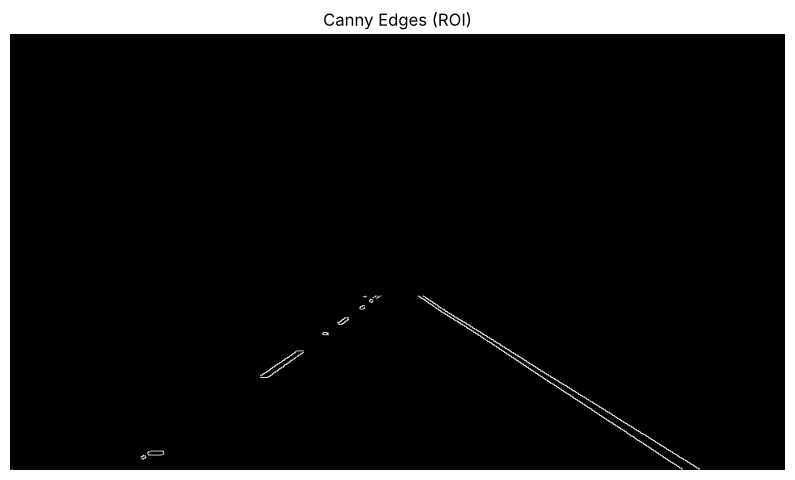

In [ ]:
road = cv2.imread('road.jpg')
g = cv2.GaussianBlur(cv2.cvtColor(road, cv2.COLOR_BGR2GRAY), (5, 5), 0)
edges = cv2.Canny(g, 50, 150)
# Region of Interest: sirf road wala triangle hissa
h, w = edges.shape
roi = np.array([[(0, h), (w, h), (w//2 + 40, int(h*0.6)), (w//2 - 40, int(h*0.6))]])
mask = np.zeros_like(edges); cv2.fillPoly(mask, roi, 255)
edges = cv2.bitwise_and(edges, mask)
show(edges, "Canny Edges (ROI)")

Standard HoughLines detected      : 13
Probabilistic HoughLinesP detected: 7


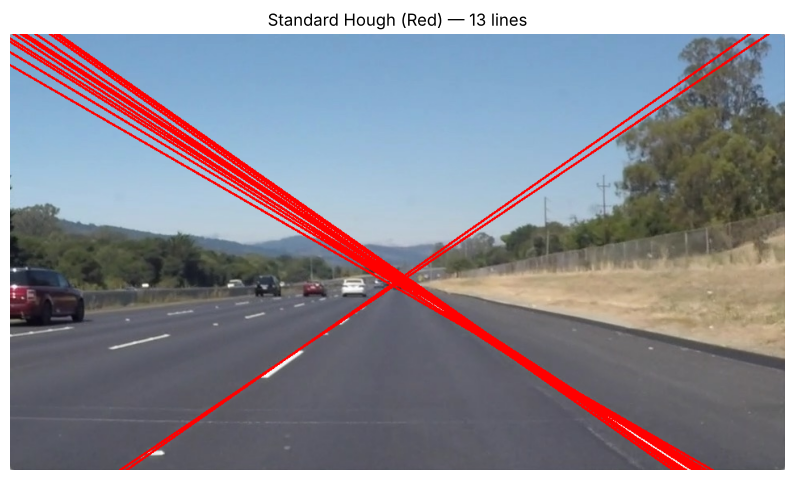

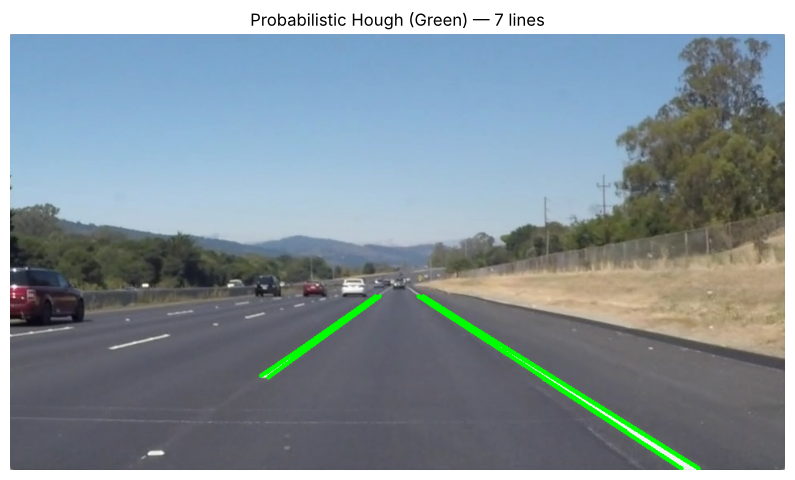

In [ ]:
# Standard Hough Transform -> RED (infinite lines, rho/theta form)
std = road.copy()
lines = cv2.HoughLines(edges, 1, np.pi/180, 70)   # threshold=70: dono lanes detect hon
n_std = 0 if lines is None else len(lines)
if lines is not None:
    for rho, theta in lines.reshape(-1, 2):
        a, b = np.cos(theta), np.sin(theta); x0, y0 = a*rho, b*rho
        p1 = (int(x0 + 2000*(-b)), int(y0 + 2000*a)); p2 = (int(x0 - 2000*(-b)), int(y0 - 2000*a))
        cv2.line(std, p1, p2, (0, 0, 255), 2)

# Probabilistic Hough Transform -> GREEN (finite segments with endpoints)
prob = road.copy()
linesP = cv2.HoughLinesP(edges, 1, np.pi/180, 40, minLineLength=40, maxLineGap=100)
n_prob = 0 if linesP is None else len(linesP)
if linesP is not None:
    for x1, y1, x2, y2 in linesP.reshape(-1, 4):
        cv2.line(prob, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 3)

print("Standard HoughLines detected      :", n_std)
print("Probabilistic HoughLinesP detected:", n_prob)
show(std,  f"Standard Hough (Red) — {n_std} lines")
show(prob, f"Probabilistic Hough (Green) — {n_prob} lines")

### Which is better for actual object boundaries?
**`cv2.HoughLinesP()` (Probabilistic) behtar hai.**

- Output mein dekho: standard method ne ek hi lane ke liye kayi near-duplicate infinite lines di (counts upar print hue hain), jab ke probabilistic ne lane ke actual hisse par hi short segments diye.
- **Standard `HoughLines()`** sirf `(ρ, θ)` return karta hai — yani ek *infinite* line. Is mein start/end points nahi hote, isliye red lines poori image ke aar-paar chali jaati hain (sky, cars, etc. ke upar bhi), chahe actual lane marking sirf chhota sa segment ho.
- **Probabilistic `HoughLinesP()`** har line ke **endpoints `(x1, y1, x2, y2)`** deta hai, to green lines sirf wahan banti hain jahan edge pixels waqai mojood hain — yani actual lane boundary ko follow karti hain. Dashed lanes ko `maxLineGap` se join bhi kar leta hai, aur `minLineLength` se chhoti noisy lines filter ho jaati hain.
- Ye random subset of edge points use karta hai, isliye **faster** bhi hai — real-time lane detection ke liye suitable.

**Conclusion:** Object boundaries (jaise lane markings) ki actual position aur extent chahiye ho to HoughLinesP use karo; HoughLines sirf line ki direction batata hai, boundary ka extent nahi.